In [10]:
import pandas as pd

df = pd.read_csv("incidents.csv")

df.shape

df.head()

df.info()

df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Incident_ID          5000 non-null   int64
 1   Category             5000 non-null   str  
 2   Subcategory          5000 non-null   str  
 3   Impact               5000 non-null   str  
 4   Urgency              5000 non-null   str  
 5   Affected_Users       5000 non-null   int64
 6   Service_Criticality  5000 non-null   str  
 7   Business_Hours       5000 non-null   str  
 8   Customer_Impact      5000 non-null   str  
 9   Reopen_Count         5000 non-null   int64
 10  Assignment_Group     5000 non-null   str  
 11  Priority             5000 non-null   str  
dtypes: int64(3), str(9)
memory usage: 740.9 KB


,Incident_ID,Category,Subcategory,Impact,Urgency,Affected_Users,Service_Criticality,Business_Hours,Customer_Impact,Reopen_Count,Assignment_Group,Priority
count,5000.000000,5000,5000,5000,5000,5000.000000,5000,5000,5000,5000.000000,5000,5000
unique,NaN,6,18,3,3,NaN,4,2,2,NaN,6,4
top,NaN,Network,Outage,Medium,Medium,NaN,Medium,No,Yes,NaN,Network Team,P3
freq,NaN,1259,449,2225,2038,NaN,1764,2516,3015,NaN,881,2569
mean,3500.500000,NaN,NaN,NaN,NaN,24.766200,NaN,NaN,NaN,0.719200,NaN,NaN
std,1443.520003,NaN,NaN,NaN,NaN,46.776258,NaN,NaN,NaN,1.092607,NaN,NaN
min,1001.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.000000,NaN,NaN
25%,2250.750000,NaN,NaN,NaN,NaN,5.000000,NaN,NaN,NaN,0.000000,NaN,NaN
50%,3500.500000,NaN,NaN,NaN,NaN,11.500000,NaN,NaN,NaN,0.000000,NaN,NaN
75%,4750.250000,NaN,NaN,NaN,NaN,27.000000,NaN,NaN,NaN,1.000000,NaN,NaN


In [11]:
df.isnull().sum()

Incident_ID            0
Category               0
Subcategory            0
Impact                 0
Urgency                0
Affected_Users         0
Service_Criticality    0
Business_Hours         0
Customer_Impact        0
Reopen_Count           0
Assignment_Group       0
Priority               0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

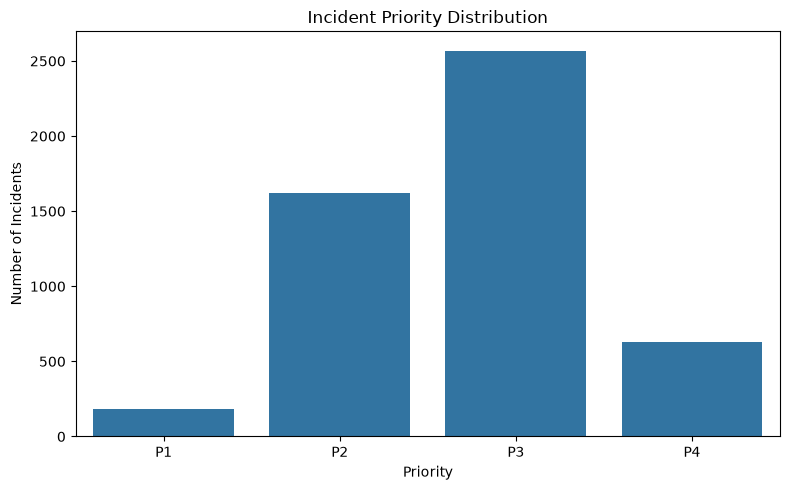

In [13]:
#Visualise the priority distribution

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Priority",
    order=["P1", "P2", "P3", "P4"]
)

plt.title("Incident Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Number of Incidents")

plt.tight_layout()
plt.savefig("priority_distribution.png")
plt.show()

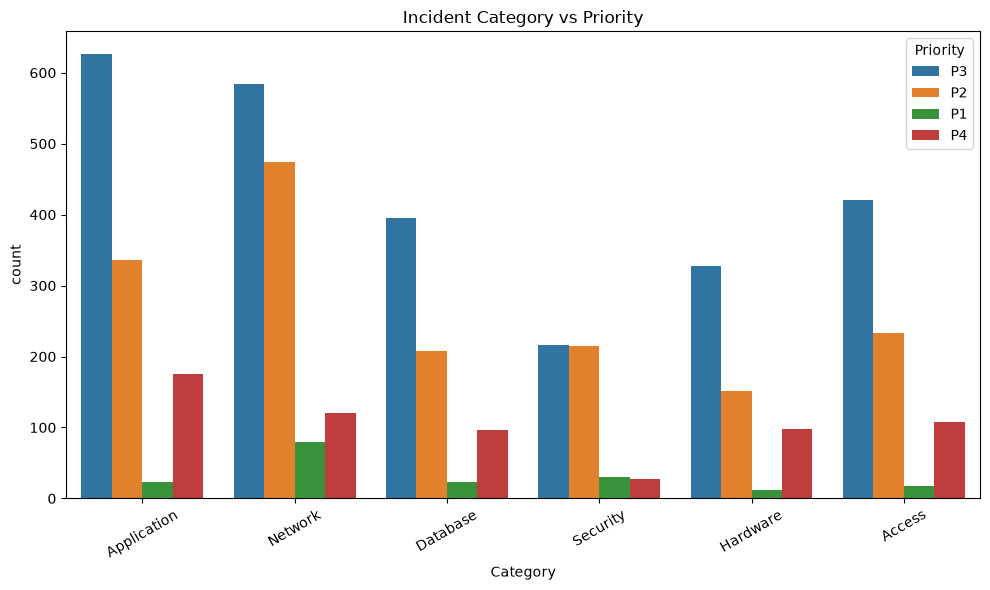

In [14]:
#Incident Category vs Priority
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Category",
    hue="Priority"
)

plt.title("Incident Category vs Priority")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

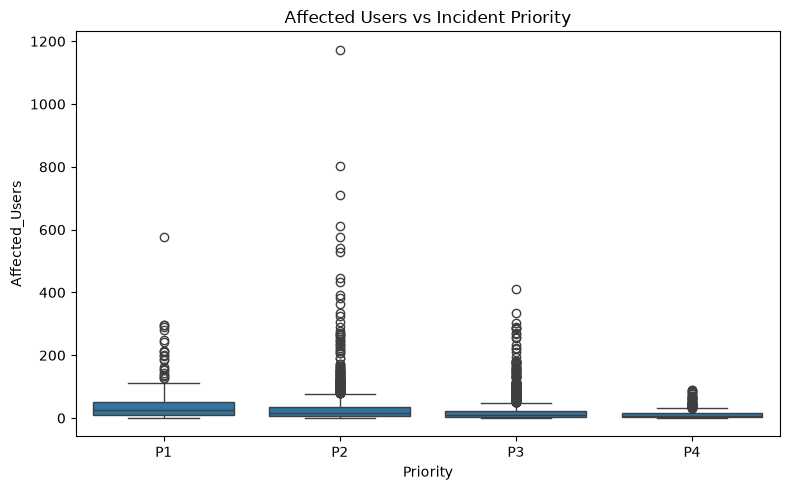

In [15]:
#Affected Users vs Incident Priority
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Priority",
    y="Affected_Users",
    order=["P1", "P2", "P3", "P4"]
)

plt.title("Affected Users vs Incident Priority")

plt.tight_layout()
plt.show()

In [16]:
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from xgboost import XGBClassifier

import matplotlib.pyplot as plt


In [17]:
df=df.drop(columns=["Incident_ID"], errors="ignore")

In [18]:
X=df.drop(columns=["Priority"])
y = df["Priority"]

In [19]:
priority_mapping={"P1": 0,"P2": 1,"P3": 2,"P4": 3}

In [20]:
y=y.map(priority_mapping)

In [21]:
y

0       2
1       1
2       1
3       1
4       1
       ..
4995    1
4996    1
4997    2
4998    1
4999    1
Name: Priority, Length: 5000, dtype: int64

In [22]:
if y.isnull().any():
    raise ValueError("Unknown or missing priority labels found.")

print("\nPriority distribution:")
print(y.value_counts().sort_index())


Priority distribution:
Priority
0     186
1    1618
2    2569
3     627
Name: count, dtype: int64


In [23]:
numeric_features = X.select_dtypes(include=["int64"]).columns.tolist()

categorical_features = X.select_dtypes(include=["str", "category", "bool"]).columns.tolist()

In [24]:
categorical_features

['Category',
 'Subcategory',
 'Impact',
 'Urgency',
 'Service_Criticality',
 'Business_Hours',
 'Customer_Impact',
 'Assignment_Group']

In [25]:
numeric_features

['Affected_Users', 'Reopen_Count']

In [26]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


In [27]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

In [28]:
numeric_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [29]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [31]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SVM": SVC(
        class_weight="balanced"
    ),

    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}


In [32]:
results = []
trained_models = {}

for name, classifier in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro_Precision": precision,
        "Macro_Recall": recall,
        "Macro_F1": f1
    })

    trained_models[name] = pipeline



Training Logistic Regression...

Training Decision Tree...

Training Random Forest...

Training SVM...

Training XGBoost...



Model comparison:
              Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
            XGBoost     0.973         0.974869      0.917714  0.942192
      Random Forest     0.945         0.941667      0.897715  0.914016
      Decision Tree     0.951         0.893951      0.894864  0.894359
Logistic Regression     0.939         0.855592      0.958637  0.891519
                SVM     0.918         0.848007      0.909770  0.874212


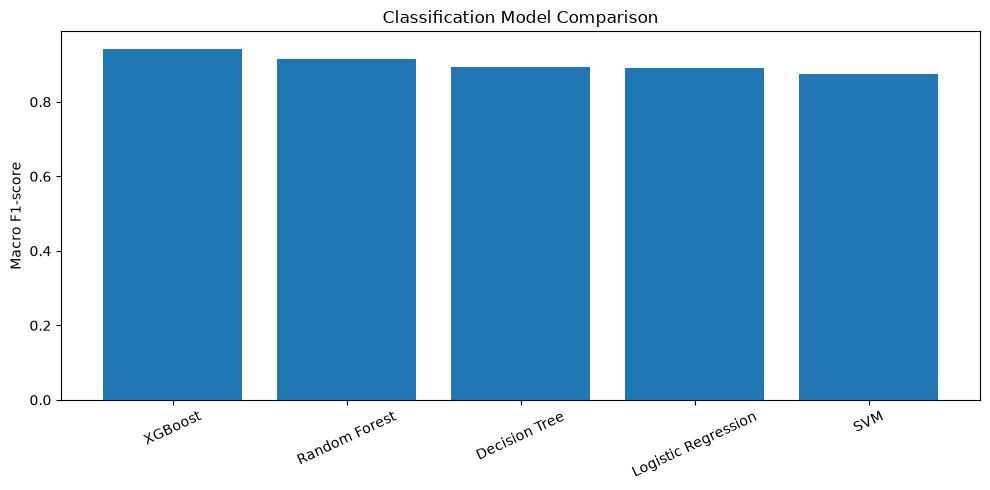

In [33]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro_F1",
    ascending=False
)

print("\nModel comparison:")
print(results_df.to_string(index=False))

results_df.to_csv(
     "model_comparison.csv",
    index=False
)

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Macro_F1"]
)

plt.title("Classification Model Comparison")
plt.ylabel("Macro F1-score")
plt.xticks(rotation=25)

plt.tight_layout()

plt.savefig(
     "model_comparison.png"
)

plt.show()


In [34]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]


In [35]:
if best_model_name == "Decision Tree":

    param_grid = {
        "classifier__max_depth": [5, 10, 15, None],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4]
    }

elif best_model_name == "Random Forest":

    param_grid = {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [10, 20, None],
        "classifier__min_samples_leaf": [1, 2]
    }

elif best_model_name == "Logistic Regression":

    param_grid = {
        "classifier__C": [0.1, 1, 10]
    }

elif best_model_name == "SVM":

    param_grid = {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"]
    }

else:

    param_grid = {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 5, 7],
        "classifier__learning_rate": [0.05, 0.1]
    }


grid_search = GridSearchCV(
    estimator=best_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("\nBest parameters:")
print(grid_search.best_params_)



Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200}



Final accuracy:
0.969

Final classification report:
              precision    recall  f1-score   support

          P1       1.00      0.70      0.83        37
          P2       0.96      0.96      0.96       324
          P3       0.97      1.00      0.98       514
          P4       1.00      0.96      0.98       125

    accuracy                           0.97      1000
   macro avg       0.98      0.90      0.94      1000
weighted avg       0.97      0.97      0.97      1000



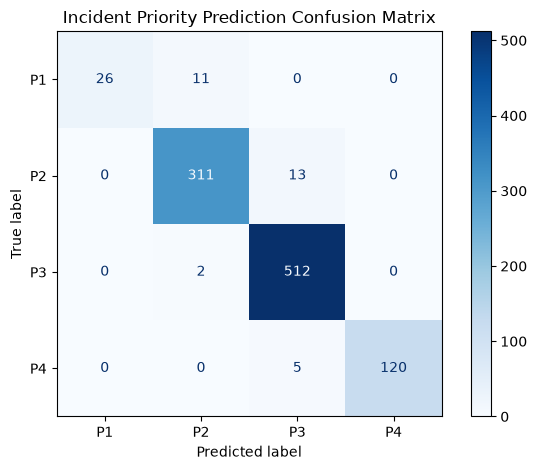

In [36]:
predictions = best_model.predict(X_test)

print("\nFinal accuracy:")
print(accuracy_score(y_test, predictions))

print("\nFinal classification report:")

print(
    classification_report(
        y_test,
        predictions,
        labels=[0, 1, 2, 3],
        target_names=["P1", "P2", "P3", "P4"],
        zero_division=0
    )
)


# --------------------------------------------------
# 14. Confusion matrix
# --------------------------------------------------

display = ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    labels=[0, 1, 2, 3],
    display_labels=["P1", "P2", "P3", "P4"],
    cmap="Blues"
)

display.ax_.set_title(
    "Incident Priority Prediction Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
     "confusion_matrix.png"
)

plt.show()



In [37]:
joblib.dump(
    best_model,
     "best_model.pkl"
)

metadata = {
    "priority_mapping": priority_mapping,
    "best_model_name": best_model_name,
    "best_parameters": grid_search.best_params_,
    "features": X.columns.tolist()
}

joblib.dump(
    metadata,
     "model_metadata.pkl"
)

print("\nModel saved successfully!")



Model saved successfully!


In [38]:
metadata

{'priority_mapping': {'P1': 0, 'P2': 1, 'P3': 2, 'P4': 3},
 'best_model_name': 'XGBoost',
 'best_parameters': {'classifier__learning_rate': 0.1,
  'classifier__max_depth': 5,
  'classifier__n_estimators': 200},
 'features': ['Category',
  'Subcategory',
  'Impact',
  'Urgency',
  'Affected_Users',
  'Service_Criticality',
  'Business_Hours',
  'Customer_Impact',
  'Reopen_Count',
  'Assignment_Group']}